# 06 - Avaliação dos modelos

O desempenho preditivo é comparado nos conjuntos de treino e teste. Para regressão são considerados MAE, MSE, RMSE, MAPE, R² e MedAE; para classificação, Accuracy, Precision, Recall, F1, ROC-AUC e PR-AUC. Matrizes de confusão, curvas e resíduos complementam a análise.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT/'data').exists(): ROOT = ROOT.parent
assert (ROOT/'src').exists(), 'Abra o notebook a partir da pasta do projeto.'
sys.path.insert(0,str(ROOT))
TAB=ROOT/'reports'/'tables'; FIG=ROOT/'reports'/'figures'
META=json.loads((ROOT/'data/processed/metadata.json').read_text(encoding='utf-8'))
print('Projeto:', ROOT)

Projeto: C:\Users\Felipe Erik\Desktop\Trabalho2IA\final\student_career_ia


## Cálculo das métricas
As métricas podem ser reconstruídas a partir dos modelos treinados e dos conjuntos de treino e teste.

In [2]:
import pickle
from src.training import prepare
from src.metrics import eval_metric
from src.expert_system import load_rules
recalculadas = []
for tarefa in ('regression', 'classification'):
    Xtr, Xte, ytr, yte = prepare(tarefa)
    for nome in ('Sistema_Especialista','Arvore_sem_limite','Arvore_ajustada','Random_Forest','Gradient_Boosting'):
        if nome == 'Sistema_Especialista':
            modelo = load_rules(tarefa)
        else:
            with (ROOT/'models'/f'{tarefa}_{nome}.pkl').open('rb') as f:
                modelo = pickle.load(f) # arquivos gerados localmente pelo projeto
        for parte, X, y in (('train',Xtr,ytr),('test',Xte,yte)):
            probabilidades = modelo.predict_proba(X)[:,1] if tarefa=='classification' and nome!='Sistema_Especialista' else None
            recalculadas.append(dict(task=tarefa,model=nome,split=parte,**eval_metric(y,modelo.predict(X),tarefa,probabilidades)))
resultados_calculados = pd.DataFrame(recalculadas)
display(resultados_calculados.round(4))

,task,model,split,MAE,MSE,RMSE,MAPE,R2,MedAE,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,regression,Sistema_Especialista,train,12.6619,257.7171,16.0536,6.2169,0.6415,10.6036,NaN,NaN,NaN,NaN,NaN,NaN
1,regression,Sistema_Especialista,test,12.5218,253.1047,15.9093,6.1618,0.6494,10.4442,NaN,NaN,NaN,NaN,NaN,NaN
2,regression,Arvore_sem_limite,train,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
3,regression,Arvore_sem_limite,test,3.7481,24.1089,4.9101,1.8354,0.9666,2.9500,NaN,NaN,NaN,NaN,NaN,NaN
4,regression,Arvore_ajustada,train,2.8739,13.4872,3.6725,1.3938,0.9812,2.3643,NaN,NaN,NaN,NaN,NaN,NaN
5,regression,Arvore_ajustada,test,3.7098,22.4710,4.7404,1.8073,0.9689,3.0794,NaN,NaN,NaN,NaN,NaN,NaN
6,regression,Random_Forest,train,0.9581,1.6743,1.2939,0.4702,0.9977,0.7272,NaN,NaN,NaN,NaN,NaN,NaN
7,regression,Random_Forest,test,2.0608,7.7013,2.7751,1.0164,0.9893,1.5477,NaN,NaN,NaN,NaN,NaN,NaN
8,regression,Gradient_Boosting,train,2.0948,7.7666,2.7869,1.0315,0.9892,1.6103,NaN,NaN,NaN,NaN,NaN,NaN
9,regression,Gradient_Boosting,test,2.1064,7.8456,2.8010,1.0376,0.9891,1.6130,NaN,NaN,NaN,NaN,NaN,NaN


## Regressão
RMSE penaliza mais os erros grandes; MAE é menos sensível a outliers. MAPE é limitado quando valores reais são zero ou próximos de zero.

,model,MAE,MSE,RMSE,MAPE,R2,MedAE
7,Random_Forest,2.0608,7.7013,2.7751,1.0164,0.9893,1.5477
9,Gradient_Boosting,2.1064,7.8456,2.8010,1.0376,0.9891,1.6130
5,Arvore_ajustada,3.7098,22.4710,4.7404,1.8073,0.9689,3.0794
3,Arvore_sem_limite,3.7481,24.1089,4.9101,1.8354,0.9666,2.9500
1,Sistema_Especialista,12.5218,253.1047,15.9093,6.1618,0.6494,10.4442


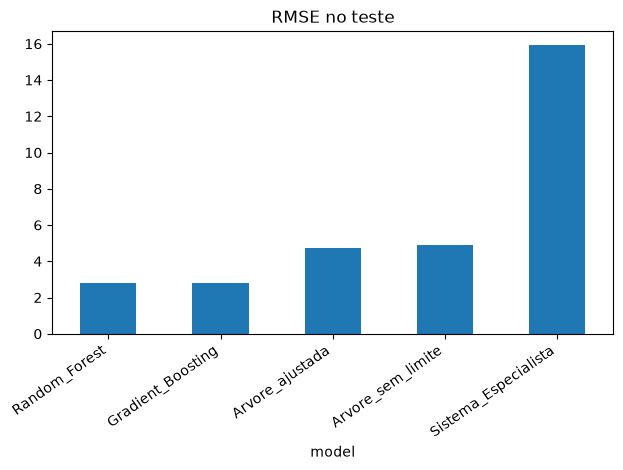

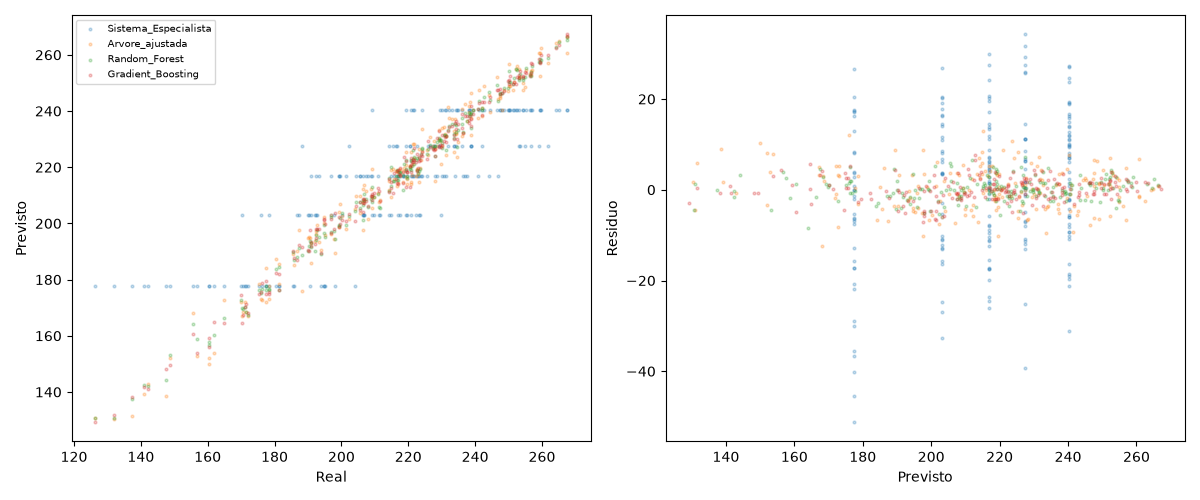

In [3]:
m=pd.read_csv(TAB/'model_metrics.csv')
reg=m[(m.task=='regression')&(m.split=='test')][['model','MAE','MSE','RMSE','MAPE','R2','MedAE']].sort_values('RMSE')
display(reg.round(4))
reg.plot(x='model',y='RMSE',kind='bar',legend=False,title='RMSE no teste');plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.show()
display(Image(filename=str(FIG/'regression_residuals.png')))

## Classificação
A classe positiva é Placed. A distribuição original é desbalanceada, então Accuracy isoladamente pode esconder falhas na classe minoritária. A avaliação também considera métricas da classe Not Placed e matrizes de confusão; considera-se a diferença entre F1 da classe positiva e médias macro.

,model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
19,Gradient_Boosting,0.8188,0.8408,0.9472,0.8909,0.8059,0.9164
17,Random_Forest,0.8177,0.8400,0.9468,0.8902,0.8034,0.9193
15,Arvore_ajustada,0.8180,0.8417,0.9445,0.8902,0.8055,0.9157
11,Sistema_Especialista,0.8000,0.8625,0.8850,0.8736,NaN,NaN
13,Arvore_sem_limite,0.7329,0.8335,0.8221,0.8278,0.6186,0.8241


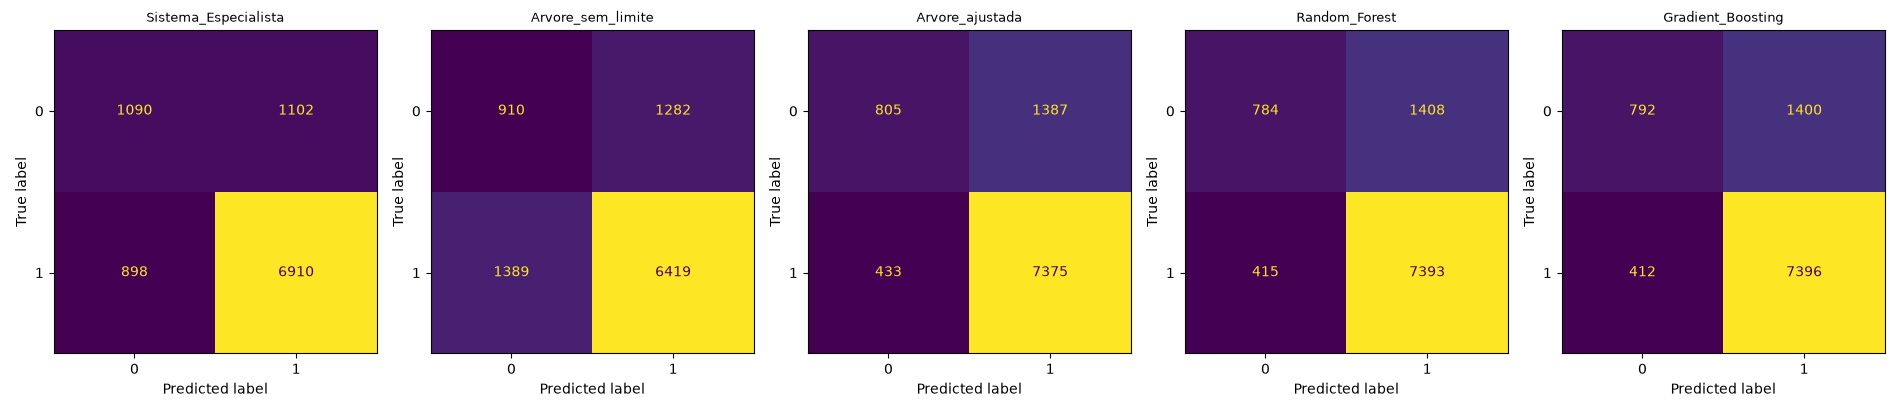

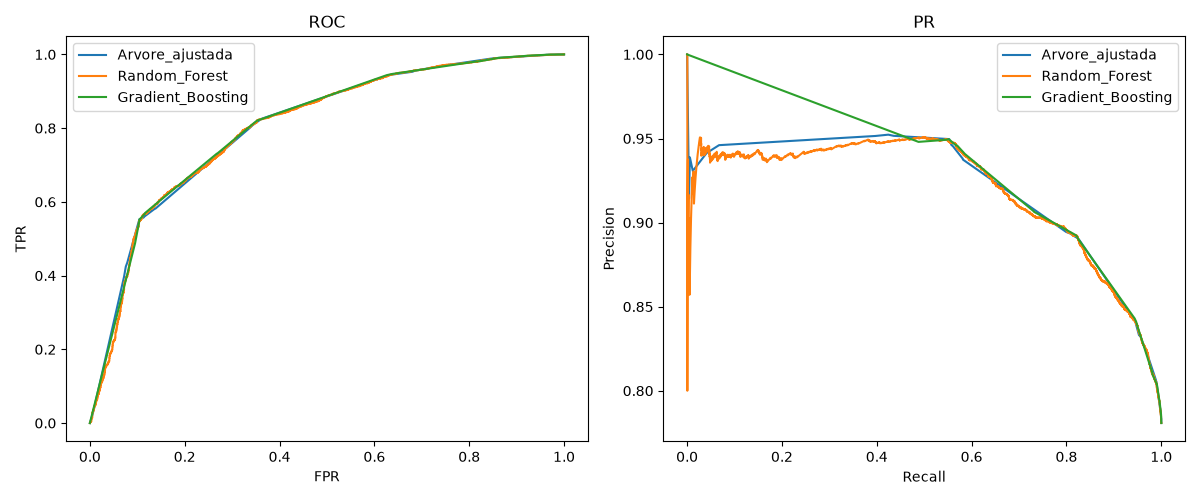

In [4]:
cls=m[(m.task=='classification')&(m.split=='test')][['model','Accuracy','Precision','Recall','F1','ROC_AUC','PR_AUC']].sort_values('F1',ascending=False)
display(cls.round(4))
display(Image(filename=str(FIG/'classification_confusion.png')))
display(Image(filename=str(FIG/'classification_roc_pr.png')))

## ROC-AUC e PR-AUC para Sistema Especialista
Os modelos Random Forest, Gradient Boosting e Decision Tree retornam predict_proba, o sistema especialista salva decisões rígidas, sem escore probabilístico calibrado. Por isso ROC-AUC e PR-AUC do especialista permanecem ausentes, sem valores inventados. Uma extensão exigiria uma pontuação contínua fundamentada ou calibração em validação, nunca no teste.

## Critério de comparação

Na regressão, RMSE atribui maior peso a erros elevados, enquanto MAE permite interpretar o erro médio na escala do alvo. Na classificação, o F1 da classe Placed orienta os ajustes realizados, mas a identificação de estudantes sem colocação profissional também requer a análise da classe Not Placed. A seleção final considera a finalidade da previsão e os custos relativos dos erros.